# EXP-001：灰色時段公平值

> 實驗紀錄與結論：[EXP-001-gray-fairness.md](EXP-001-gray-fairness.md)

**問題：**「不可連續三天灰色時段」只是硬性上限。在規定之內，灰色時段（00-02、02-04、04-06、12-14）
仍可能集中在少數人身上。

**改進：** 排灰色班時，額外依「當月灰色節數 ÷ 上班天數」排序（權重 3），並對昨天、前天站過灰色的人扣分。

**這份 notebook：** 讀取重現腳本產生的原始數據，比較「移除灰色公平值」與「現行版本」。兩者使用完全相同的出勤資料，
只差在灰色公平值的開關。所有統計量以 `numpy`／`scipy` 重新計算。

## 重現方式

```bash
npm run experiment -- scripts/experiments/exp-001-gray-fairness.ts    # 產生 data/exp-001/
.venv/Scripts/jupyter nbconvert --to notebook --execute --inplace docs/experiments/EXP-001-gray-fairness.ipynb
```

> EXP-001 最初的 1-seed 數據來自當時沒有保留的臨時腳本，無法逐字重現。這裡使用相同的四個情境，改為 30 seeds。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nbutils import AQUA, BLUE, INK, MUTED, assert_close, load, mean_ci, mw, settle_all

cases = load("exp-001", "cases")
persons = load("exp-001", "persons")
runs = load("exp-001", "runs")

COLOR = {"noGray": AQUA, "current": BLUE}
LABEL = {"noGray": "Without gray fairness", "current": "Current (with gray fairness)"}
CASE_EN = {"A": "14 people", "B": "20 people", "C": "50 people", "D": "10 people (tight)"}
print(f"persons: {len(persons):,} rows, runs: {len(runs)}, seeds: {runs.seed.nunique()}")
cases

persons: 5,640 rows, runs: 240, seeds: 30


,case,name,desc,n_people,n_leaders
0,A,14 人（哨長 8）,20% 休假,14,8
1,B,20 人（哨長 10）,20% 休假,20,10
2,C,50 人（哨長 27）,30% 休假,50,27
3,D,10 人（哨長 6）人力吃緊,10% 休假,10,6


## 1. 硬性規定與交叉驗證

- 獨立 checker（以小時計算，不使用排哨演算法的邏輯）找到的違規數必須為 0。
- 從每人的原始數據重算月結算偏差，必須與 TypeScript 腳本輸出的值一致。

In [2]:
assert runs.violations.sum() == 0, "發現違規！"
print("✓ 違規數：0")

py = settle_all(persons, ["case", "variant", "seed"])
both = runs.merge(py, on=["case", "variant", "seed"])
assert_close(both.ts_rms, both.rms, "總節數偏差 RMS")
assert_close(both.ts_rms_gray, both.rms_gray, "灰色偏差 RMS")

✓ 違規數：0


✓ 總節數偏差 RMS：與 TypeScript 結果一致（最大差異 4.7e-12）
✓ 灰色偏差 RMS：與 TypeScript 結果一致（最大差異 5.0e-12）


## 2. 每人每月的灰色負擔

每個點是一個人在一個月（一個 seed）中的「灰色節數 ÷ 上班天數」。分布越窄，代表灰色時段分配越平均。

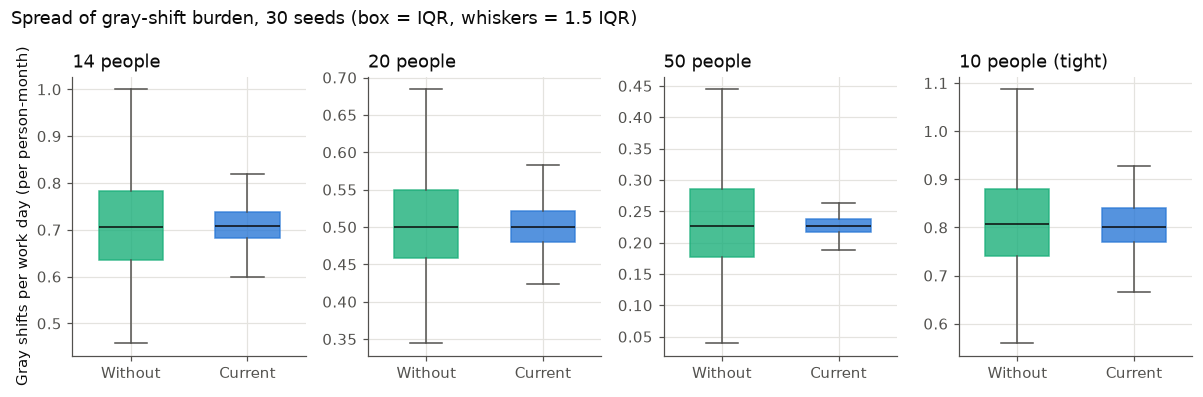

In [3]:
cur = persons[persons.work_days > 0].assign(rate=lambda d: d.gray / d.work_days)
fig, axes = plt.subplots(1, 4, figsize=(11, 3.6), sharey=False)
for ax, (cid, g) in zip(axes, cur.groupby("case")):
    data = [g[g.variant == v].rate for v in ["noGray", "current"]]
    bp = ax.boxplot(data, widths=0.55, patch_artist=True, showfliers=False,
                    medianprops={"color": INK}, whiskerprops={"color": MUTED}, capprops={"color": MUTED})
    for b, v in zip(bp["boxes"], ["noGray", "current"]):
        b.set(facecolor=COLOR[v], edgecolor=COLOR[v], alpha=0.8)
    ax.set_xticks([1, 2], ["Without", "Current"])
    ax.set_title(CASE_EN[cid])
axes[0].set_ylabel("Gray shifts per work day (per person-month)")
fig.suptitle("Spread of gray-shift burden, 30 seeds (box = IQR, whiskers = 1.5 IQR)", x=0.01, ha="left", color=INK)
plt.tight_layout()
plt.show()

## 3. 灰色偏差 RMS（每個 seed 成對比較）

灰色偏差 = 每人「實際灰色節數 − 應得灰色節數」，應得 = 上班天數 × 全單位平均。
每條線連接同一個 seed（同一組出勤）在兩個版本下的結果。

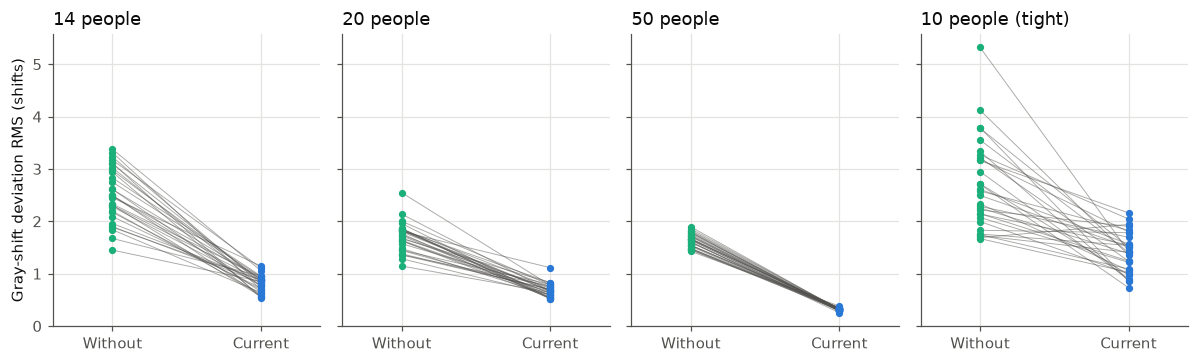

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3.4), sharey=True)
for ax, (cid, g) in zip(axes, py.groupby("case")):
    a = g[g.variant == "noGray"].sort_values("seed").rms_gray.to_numpy()
    b = g[g.variant == "current"].sort_values("seed").rms_gray.to_numpy()
    for y0, y1 in zip(a, b):
        ax.plot([0, 1], [y0, y1], color=MUTED, lw=0.6, alpha=0.5)
    ax.scatter(np.zeros(len(a)), a, s=14, color=COLOR["noGray"], zorder=3)
    ax.scatter(np.ones(len(b)), b, s=14, color=COLOR["current"], zorder=3)
    ax.set_xticks([0, 1], ["Without", "Current"])
    ax.set_xlim(-0.4, 1.4)
    ax.set_title(CASE_EN[cid])
axes[0].set_ylabel("Gray-shift deviation RMS (shifts)")
plt.tight_layout()
plt.show()

## 4. 結果總表

p 為灰色偏差 RMS 的 Mann-Whitney U test（雙尾，30 vs 30 seeds）。

In [5]:
rows = []
for cid in cases.case:
    b = py[(py.case == cid) & (py.variant == "noGray")].sort_values("seed")
    a = py[(py.case == cid) & (py.variant == "current")].sort_values("seed")
    rb = runs[(runs.case == cid) & (runs.variant == "noGray")]
    ra = runs[(runs.case == cid) & (runs.variant == "current")]
    rows.append({
        "case": f"{cid} {cases.set_index('case').name[cid]}",
        "gray min～max (without → current)": f"{b.gray_min.mean():.1f}～{b.gray_max.mean():.1f} → {a.gray_min.mean():.1f}～{a.gray_max.mean():.1f}",
        "gray RMS without": mean_ci(b.rms_gray), "gray RMS current": mean_ci(a.rms_gray),
        "p": mw(a.rms_gray, b.rms_gray)[1],
        "max gray days in 7": f"{rb.max_gray7.mean():.1f} → {ra.max_gray7.mean():.1f}",
        "total RMS": f"{b.rms.mean():.2f} → {a.rms.mean():.2f}",
        "gaps / month": f"{rb.gaps.mean():.1f} → {ra.gaps.mean():.1f}",
    })
summary = pd.DataFrame(rows).set_index("case")
summary.style.format({"p": "{:.1e}"})

,gray min～max (without → current),gray RMS without,gray RMS current,p,max gray days in 7,total RMS,gaps / month
case,,,,,,,
A 14 人（哨長 8）,12.9～21.5 → 14.0～19.6,2.51 ± 0.19,0.81 ± 0.06,2.9e-11,5.0 → 5.0,0.43 → 0.45,0.6 → 0.9
B 20 人（哨長 10）,9.2～15.2 → 9.8～14.2,1.70 ± 0.10,0.68 ± 0.05,2.9e-11,4.0 → 4.1,0.83 → 0.84,0.0 → 0.0
C 50 人（哨長 27）,1.4～8.4 → 3.4～6.1,1.64 ± 0.05,0.32 ± 0.01,2.9e-11,3.5 → 2.1,0.34 → 0.36,0.0 → 0.0
D 10 人（哨長 6）人力吃緊,16.3～24.9 → 17.6～23.4,2.69 ± 0.32,1.40 ± 0.14,2.3e-09,5.0 → 5.0,0.34 → 0.36,16.6 → 18.1


## 5. 代價（trade-off）

灰色公平值讓演算法在排灰色班時多一個考量，可能犧牲兩件事：

1. **總節數的公平性**：排序不再只看總節數。
2. **人力吃緊時的空缺**：演算法更堅持平均分配灰色班，沒有餘裕時較容易卡住。

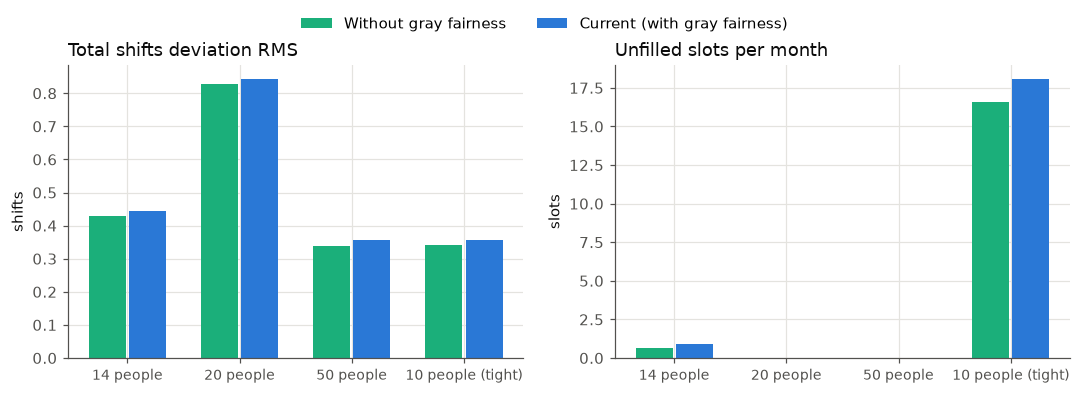

人力吃緊（10 人）空缺／月： 16.6 ± 1.3 → 18.1 ± 1.3 (p = 0.085)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
x = np.arange(len(cases))
for k, v in enumerate(["noGray", "current"]):
    m = py[py.variant == v].groupby("case").rms.mean().reindex(cases.case)
    axes[0].bar(x + (k - 0.5) * 0.36, m, width=0.33, color=COLOR[v], label=LABEL[v])
    gm = runs[runs.variant == v].groupby("case").gaps.mean().reindex(cases.case)
    axes[1].bar(x + (k - 0.5) * 0.36, gm, width=0.33, color=COLOR[v])
for ax, t, yl in zip(axes, ["Total shifts deviation RMS", "Unfilled slots per month"], ["shifts", "slots"]):
    ax.set_xticks(x, [CASE_EN[c] for c in cases.case], fontsize=9)
    ax.set_title(t)
    ax.set_ylabel(yl)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout()
plt.show()

d = runs[runs.case == "D"]
print("人力吃緊（10 人）空缺／月：", mean_ci(d[d.variant == "noGray"].gaps, 1), "→", mean_ci(d[d.variant == "current"].gaps, 1),
      f"(p = {mw(d[d.variant == 'current'].gaps, d[d.variant == 'noGray'].gaps)[1]:.3f})")

## 6. 在 9 個標準情境中重新驗證

上面的四個情境來自 EXP-001 的原始設計。EXP-004 的消融實驗在 9 個標準情境中做了同樣的比較
（[EXP-004 原始數據](data/exp-004/)），這裡從那份數據重算。

In [7]:
p4 = load("exp-004", "persons")
p4 = p4[p4.variant.isin(["current", "noGray"])]
s4 = settle_all(p4, ["scenario", "variant", "seed"])
# 結構性人力不足的 S4～S6 只跑了現行版本，不參與比較
order = sorted(s4[s4.variant == "noGray"].scenario.unique(), key=lambda s: int(s[1:]))
r4 = load("exp-004", "runs")
rows = []
for sc in order:
    a = s4[(s4.scenario == sc) & (s4.variant == "current")].sort_values("seed")
    b = s4[(s4.scenario == sc) & (s4.variant == "noGray")].sort_values("seed")
    rows.append({"scenario": sc, "gray RMS without": b.rms_gray.mean(), "gray RMS current": a.rms_gray.mean(),
                 "p (gray)": mw(a.rms_gray, b.rms_gray)[1],
                 "total RMS without": b.rms.mean(), "total RMS current": a.rms.mean(), "p (total)": mw(a.rms, b.rms)[1]})
    ga = r4[(r4.scenario == sc) & (r4.variant == "current")].gaps
    gb = r4[(r4.scenario == sc) & (r4.variant == "noGray")].gaps
    rows[-1].update({"gaps without": gb.mean(), "gaps current": ga.mean(),
                     "p (gaps)": mw(ga, gb)[1] if ga.sum() + gb.sum() else float("nan")})
abl = pd.DataFrame(rows).set_index("scenario")
abl.style.format("{:.3f}").format({"p (gray)": "{:.1e}", "p (total)": "{:.3f}", "p (gaps)": "{:.3f}"}, na_rep="—")

,gray RMS without,gray RMS current,p (gray),total RMS without,total RMS current,p (total),gaps without,gaps current,p (gaps)
scenario,,,,,,,,,
S1,2.239333,0.397135,2.9e-11,0.404835,0.443567,0.114,0.000000,0.000000,—
S2,2.273318,0.777949,3.5e-11,0.345573,0.378989,0.065,1.200000,2.233333,0.005
S3,1.641393,0.315698,2.9e-11,0.337321,0.357671,0.032,0.000000,0.000000,—
S7,1.681751,0.580990,4.7e-11,0.340671,0.357988,0.231,0.000000,0.000000,—
S8,2.088536,0.452577,2.9e-11,0.641753,0.651314,0.564,0.000000,0.000000,—
S9,2.092737,0.503952,2.9e-11,0.362910,0.448734,0.000,0.000000,0.000000,—
S10,1.366477,0.543360,2.9e-11,0.385436,0.439939,0.001,0.000000,0.000000,—
S11,2.025049,0.535805,2.9e-11,0.638864,0.677076,0.408,0.000000,0.033333,0.317
S12,2.029479,0.614954,2.8e-11,0.342922,0.363471,0.183,0.000000,0.000000,—


## 結論

- **灰色時段明顯更平均。** 四個原始情境與 9 個標準情境中，灰色偏差 RMS 全部顯著下降（p < 0.001），約降為原本的 1/2 到 1/6。
- **總節數公平性有小幅代價。** 總節數偏差 RMS 略增（多數情境 < 0.1 節），部分情境達統計顯著。
  EXP-001 最初「不影響總節數公平性」的說法因此被修正。
- **人力吃緊時空缺可能略增。** S2（12 人）每月多約 1 格空缺，達統計顯著（p ≈ 0.005）；
  10 人的情境多約 1.5 格，但未達顯著（p ≈ 0.085）。其餘情境都沒有空缺。
- **「7 日內最多灰色天」只有大單位改善。** 小單位每天的灰色格數相對人數太多，是結構性限制（見 [EXP-003](EXP-003-manpower-thresholds.md)）。